# 被刪掉的航班，會改變我們看到的準時表現嗎？

題目 E｜2013 nycflights13｜缺失值處理 × PCA 敏感度分析

**主要結論**：完整列刪除將平均抵達延誤由 6.90 降到 4.76 分鐘；各策略自行標準化時，PC1／PC2 大致穩定，但固定尺度後差異變大。

本 notebook 包含實際執行的數值、六個篩選／矩形框選輸出快照及其完整條件。圖像是程式操作的輸出快照，非聲稱由滑鼠操作擷取的瀏覽器螢幕截圖。若老師嚴格要求 UI 截圖，請按下面六步在互動工具操作後補拍。

資料、程式、圖像與草稿由 Codex 協助。AI 基準為同一對話的初版，非獨立盲測；反思請依本人理解審閱。


## 0. 一鍵重現：從上到下執行所有儲存格

1. **Google Colab**：將完整繳交包 ZIP 與本 notebook 都上傳到 Colab 左側「檔案」。按 **全部執行**；首格會辨識 ZIP 內容並自動解壓出 `flight_eda/`。左側只有 ZIP、尚未解壓時也可以開始執行。Colab 重新連線後，檔案可能消失，需重新上傳 ZIP。
2. **本機 Jupyter**：先解壓 ZIP，保留 `analysis.ipynb`、`src/`、`baseline/`、`data/raw/` 在同一個 `flight_eda` 資料夾。建議 Python 3.11，在 `flight_eda` 執行 `python -m pip install -r requirements.txt`，然後按 **Run All／執行所有儲存格**。
3. 單獨下載 `.ipynb` 不含約 35 MB 的原始 CSV，無法重現。分析會從原始 CSV 重新計算，不依賴隨包附上的舊 `output/`。整體計算包含 20 次固定種子的熱卡抽樣，可能需要數分鐘。末格會核對樣本數、三種策略與六個操作結果，顯示「重現成功」。

如果第一格顯示缺少套件，請在**目前 notebook 的 Python 環境**安裝 `requirements.txt` 後重新啟動 kernel 再執行。

In [1]:
# Colab 可直接從左側已上傳的完整 ZIP 解壓；本機則定位已解壓的專案。
from pathlib import Path
import sys, os, json, importlib.util
from zipfile import ZipFile, BadZipFile

def find_project(start):
    candidates = []
    for parent in [start, *start.parents]:
        candidates.extend((parent, parent / 'flight_eda'))
    for candidate in candidates:
        if (candidate / 'src/analysis.py').is_file() and (candidate / 'requirements.txt').is_file():
            return candidate.resolve()
    raise FileNotFoundError('找不到 flight_eda 專案。請解壓完整繳交包，並從該資料夾或其上層開啟 notebook。')

def unpack_uploaded_project(start):
    # 只辨識本作業的完整繳交包，不解壓無關的 ZIP。
    directories = [start, *list(start.parents)[:2]]
    if Path('/content').is_dir() and Path('/content') not in directories:
        directories.append(Path('/content'))
    needed = {'flight_eda/src/analysis.py', 'flight_eda/requirements.txt',
              'flight_eda/data/raw/flights.csv', 'flight_eda/data/raw/weather.csv'}
    for directory in directories:
        for archive in sorted(directory.glob('*.zip')):
            try:
                with ZipFile(archive) as bundle:
                    names = set(bundle.namelist())
                    if not needed.issubset(names):
                        continue
                    target_root = directory.resolve()
                    for member in bundle.infolist():
                        target = (target_root / member.filename).resolve()
                        if not target.is_relative_to(target_root):
                            raise ValueError(f'ZIP 含不安全路徑：{member.filename}')
                    bundle.extractall(target_root)
                print(f'已解壓完整繳交包：{archive.name}')
                return
            except BadZipFile:
                continue
    raise FileNotFoundError('找不到完整繳交包 ZIP。請將最新的「題目E_期中口頭報告_繳交包.zip」上傳至 Colab 左側檔案區，再按全部執行。')

try:
    ROOT = find_project(Path.cwd().resolve())
except FileNotFoundError:
    unpack_uploaded_project(Path.cwd().resolve())
    ROOT = find_project(Path.cwd().resolve())
required = {'numpy':'numpy', 'pandas':'pandas', 'scipy':'scipy', 'sklearn':'scikit-learn',
            'matplotlib':'matplotlib', 'plotly':'plotly', 'ipywidgets':'ipywidgets', 'IPython':'ipython'}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise ModuleNotFoundError(f'缺少 {missing}；請在目前 notebook 的 Python 環境執行：{sys.executable} -m pip install -r "{ROOT / "requirements.txt"}"，重啟 kernel 後再 Run All。')
raw_files = [ROOT / 'data/raw/flights.csv', ROOT / 'data/raw/weather.csv']
absent = [str(path) for path in raw_files if not path.is_file()]
if absent:
    raise FileNotFoundError(f'缺少原始 CSV：{absent}。請解壓完整繳交包；只上傳 ipynb 不足以重現。')
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.mplcache'))
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')
os.environ.setdefault('OMP_NUM_THREADS', '1')
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from IPython.display import display, Image, Markdown
from download_data import verify_or_download
verify_or_download()
print(f'專案：{ROOT}\nPython：{sys.version.split()[0]} ({sys.executable})')


flights 33206996 bytes: SHA-256 and Git blob verified
weather 2391865 bytes: SHA-256 and Git blob verified
專案：/Users/lichenghao/Desktop/數據探索的統計思維/flight_eda
Python：3.11.7 (/opt/anaconda3/bin/python)


## 1. AI 基準報表
先保存初版提示詞與原始輸出，再做缺失機制診斷。封存檔不在正式分析中改寫。完整文字與機器可讀輸出在 baseline/，PDF 附錄 A 也保留全文。

### 完整提示詞
請使用 nycflights13 的原始 flights 與 weather 資料，產生一份完整的探索式資料分析報表，供課堂作業作為 AI 初版基準。
以航班為分析單位，依 origin 與 time_hour 將 weather 左連接至 flights。分析 dep_delay、arr_delay、air_time、distance、temp、dewp、humid、wind_speed、precip、visib、pressure；機場、航空公司及月份可作分群資訊。
報表需包含資料規模與欄位意義、描述統計、缺失比例、主要分布與離群值、變數相關、機場比較、標準化 PCA 的解釋變異及主成分詮釋，並列出限制與後續建議。產生必要圖表與可重跑的程式。
如需處理缺失，請說明採用的方法。只陳述由實際運算支持的結果，不虛構統計數字，不宣稱因果關係。

執行紀錄說明：這段提示詞是本次 Codex 作業流程中明確設定的初版 EDA 子任務，並非宣稱來自另一個獨立或無前文的 AI 對話。執行時 Codex 已看過作業要求及課堂投影片。先執行 src/baseline.py、產生下列初版輸出並封存，再進行正式缺失診斷。這是前後版本比較，不是盲測或不同模型能力評比。


### 完整初版輸出
AI 初版探索式資料分析報表
工具：Codex；產生日期：2026-10-26。數值由 src/baseline.py 對原始 CSV 實際計算。

一、資料與分析範圍
航班表共有 336,776 列，天氣表有 26,115 列。分析單位為航班，機場包含 EWR、JFK、LGA。以 origin 與 time_hour 左連接，已驗證天氣鍵值唯一且合併後列數未增加。1,556 班找不到對應天氣紀錄。
分析包含 11 個數值變數：出發與抵達延誤及空中時間以分鐘計，距離以英里計；溫度、露點為華氏度，濕度為百分比，風速為 mph，降水為英吋，能見度為英里，氣壓為毫巴。機場及航空公司是類別資訊，不納入這次 PCA。

二、缺失值概況
合併後 dep_delay 缺 8,255 筆（2.451%），arr_delay 與 air_time 各缺 9,430 筆（2.800%）；distance 沒有缺失。temp、dewp、humid 各缺 1,573 筆（0.467%），wind_speed 缺 1,634 筆（0.485%），precip 與 visib 各缺 1,556 筆（0.462%），pressure 缺 38,788 筆（11.517%）。
氣壓的缺失率最高，應優先注意。本初版先以這 11 欄的完整個案進行 PCA，留下 291,140 班，約為全部的 86.45%。這是一個方便建立基準的處理方式，其代表性尚未檢驗；不能因缺失比例較小就認定刪除沒有偏誤。沒有把取消航班的延誤補成零。

三、描述統計、分布與離群值
完整的逐變數樣本數、平均數、標準差、最小值、1%、25%、50%、75%、99% 分位數及最大值，保留於 descriptive.csv。圖 baseline_distributions.png 顯示抵達延誤的右側長尾，以及各欄缺失比例。
抵達延誤最小為 -86 分鐘，最大為 1,272 分鐘；負值代表提早抵達，因此不應當作錯誤刪除。機場的平均抵達延誤為正、中位數為負，表示平均數容易被長延誤拉高。直方圖只顯示 -100 至 600 分鐘，範圍外資料仍保留在統計計算中。
原始風速最大值為 1,048.36058 mph，值得查核。本初版保留原值，沒有自行推斷正確數值。長尾延誤與極端風速可能影響 PCA，後續應做品質檢查及敏感度分析。

四、機場比較
以有觀測抵達延誤的航班計算，EWR 的 n=117,127、平均延誤 9.107 分鐘、中位數 -4；JFK 的 n=109,079、平均 5.551、中位數 -6；LGA 的 n=101,140、平均 5.783、中位數 -5。
按這項未調整指標，JFK 的平均延誤最低，EWR 最高。但這只描述有抵達延誤紀錄的航班，未將取消列入，也未控制航線、航空公司、月份及時段，不能直接解讀為機場本身的效率或整體旅行可靠度。

五、相關性
成對可用觀測的 Pearson 相關顯示：空中時間與距離 r=0.991，出發與抵達延誤 r=0.915，溫度與露點 r=0.882，濕度與能見度 r=-0.549。這些關係分別符合航程、延誤延續及天氣的直觀結構。
完整相關矩陣保留於 correlations.csv，圖於 baseline_pca.png。各對相關使用的有效樣本可能不同，這不是同一個完整資料相關矩陣，不能不經檢查直接作為後續 PCA 的輸入。相關不代表因果。

六、標準化 PCA
由於分鐘、英里及氣象單位不同，先在完整個案內逐欄減去平均並除以標準差，再擬合 PCA。PC1 解釋 22.380%，PC2 18.316%，PC3 16.707%；前兩項合計 40.696%。前五項合計約 82.435%。二維圖方便視覺化，但不能代表大部分變異已由兩軸保留。
以單位長度的特徵向量係數解讀，PC1 主要正向係數為露點 0.537、溫度 0.418、濕度 0.406，負向為能見度 -0.272、氣壓 -0.266；可暫稱「暖濕與能見度的綜合軸」，但也含有延誤成分。PC2 的空中時間與距離係數分別為 -0.669、-0.674，可暫稱「航程軸」。PC3 的兩種延誤係數約 0.58，可暫稱「延誤軸」。主成分正負方向本身沒有固定意義。
本初版只分析一種缺失處理，因此尚不能回答這些軸在其他策略下是否穩定。完整係數保留於 pca_vectors.csv。

七、限制與後續建議
本報表描述的是 2013 年紐約出發的航班，不能外推所有城市或年度。完整個案分析可能排除有系統差異的航班；天氣缺值也可能與觀測方式或時段有關。取消、轉降或其他不完整飛行紀錄不能只看一個 NA 就一概判定。
下一步應追查共同缺失及有無缺失群差異，比較不同處理方法，查核風速極端值，並用機場、航空公司、月份及時段作互動分層。這些尚未完成的檢驗不能由本初版的表格取代。

完整輸出組成：本文件、statistics.json、descriptive.csv、missing.csv、airports.csv、correlations.csv、pca_vectors.csv、baseline_distributions.png、baseline_pca.png，及產生數值的 src/baseline.py。PDF 附錄將納入本文件全文、提示詞、數值表及圖；機器可讀的完整檔案保留在 baseline 目錄。


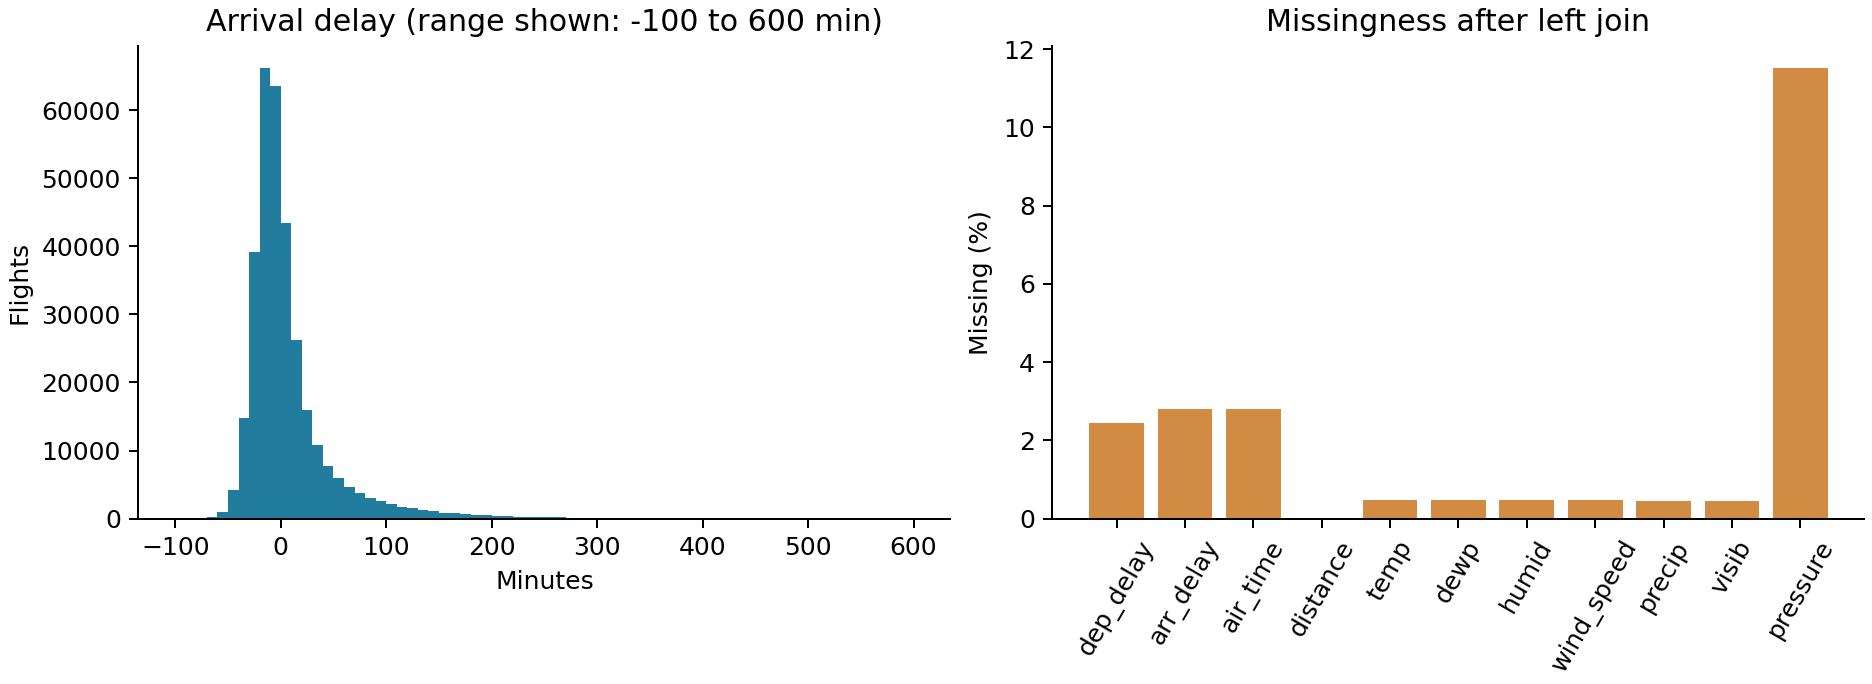

In [2]:
# 第一部分：展示事先封存的 AI 初版，避免看過正式結果後改寫基準。
display(Markdown('### 完整提示詞\n'+(ROOT/'baseline/prompt.txt').read_text()))
display(Markdown('### 完整初版輸出\n'+(ROOT/'baseline/ai_output.txt').read_text()))
display(Image(filename=str(ROOT/'baseline/baseline_distributions.png')))

## 2. 缺失診斷與三策略分析
主程式從兩個原始 CSV 讀入，核對左連接鍵、保留缺失來源，執行所有診斷、三種策略、PCA、補值遮蔽檢查與圖表。固定 seed=20261026，HOTDECK 重複 20 次；不是把熱卡重抽冒稱正式 MI。

In [3]:
# 第二至四部分的計算入口：每次 Run All 都從原始 CSV 重新計算，不讀舊的分析結果。
from analysis import run
run(draws=20)

Prepared data 336776 flights
Donor draw 5 / 20
Donor draw 10 / 20
Donor draw 15 / 20
Donor draw 20 / 20
strategy      n  retained_pct_eligible  arr_delay_mean  arr_delay_sd  pressure_mean  pressure_sd  humid_mean  rain_pct  visib_mean  pc1_pct  pc2_pct  pc12_pct  k80  pc1_pc2_gap  pc2_pc3_gap
     CCA 291140                88.9395          4.7596       41.9530      1017.9000       7.4198     56.1480    3.1006      9.5873  22.3800  18.3157   40.6957    5       0.4471       0.1770
    MEAN 327346               100.0000          6.8954       44.6333      1017.8993       6.9981     59.2293    6.8640      9.2895  22.5508  18.3229   40.8737    5       0.4651       0.1742
 HOTDECK 327346               100.0000          6.8954       44.6333      1017.5796       7.4860     59.2182    6.4400      9.2901  22.8749  18.3247   41.1996    5       0.5005       0.1766
strategy  pc1_cosine  pc2_cosine  pc1_score_r  pc2_score_r  top2_max_angle_deg  top3_max_angle_deg top3_axis_matching
     CCA      1.00

,variable,source_unit,source_missing_n,source_n,joined_original_missing_n,unmatched_contribution_n,qc_added_missing_n,analysis_missing_n,analysis_missing_pct
0,dep_delay,flight,8255,336776,8255,0,0,8255,2.451184
1,arr_delay,flight,9430,336776,9430,0,0,9430,2.800081
2,air_time,flight,9430,336776,9430,0,0,9430,2.800081
3,distance,flight,0,336776,0,0,0,0,0.000000
4,temp,station_hour,1,26115,1573,1556,0,1573,0.467076
5,dewp,station_hour,1,26115,1573,1556,0,1573,0.467076
6,humid,station_hour,1,26115,1573,1556,0,1573,0.467076
7,wind_speed,station_hour,4,26115,1634,1556,0,1634,0.485189
8,precip,station_hour,0,26115,1556,1556,0,1556,0.462028
9,visib,station_hour,0,26115,1556,1556,0,1556,0.462028


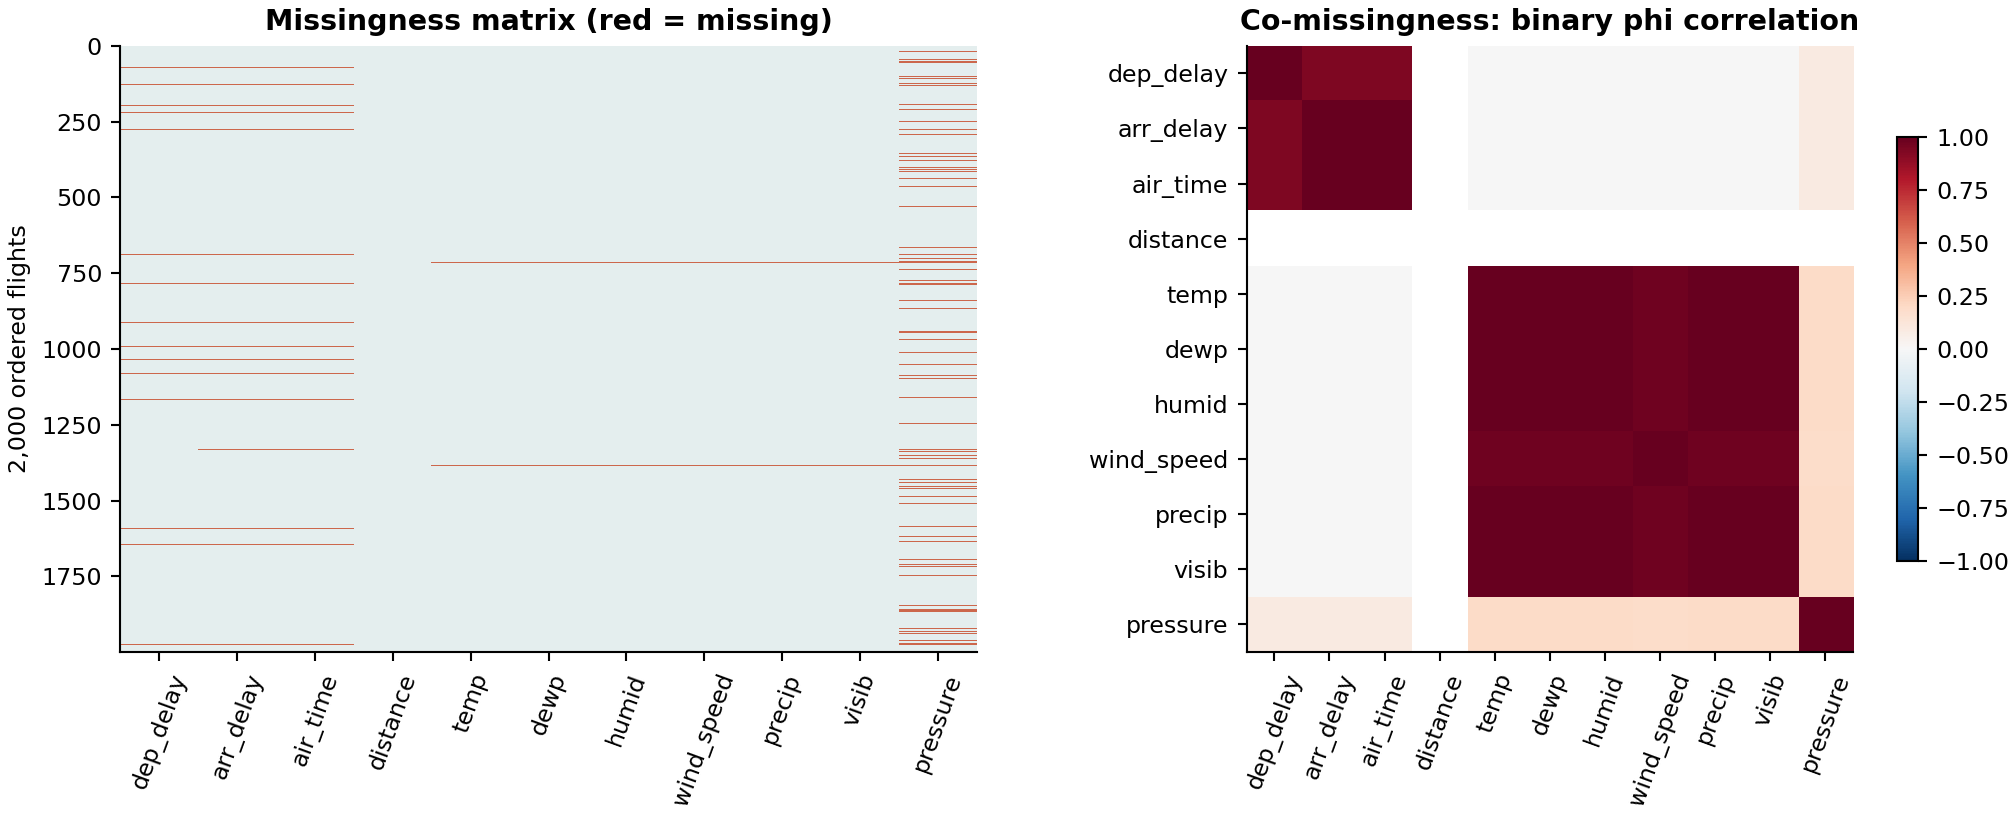

,R,n,rain_pct,humid_mean,visib_mean,precip_mean
0,False,23386,3.493543,59.766232,9.549708,0.001691
1,True,2729,34.151704,86.223185,6.733082,0.028274


,missing_indicator,unit,variable,missing_group_n,observed_group_n,missing_mean,observed_mean,missing_median,observed_median,SMD
0,pressure,station_hour,temp,2728,23386,55.529787,55.228967,57.20000,55.04000,0.017611
1,pressure,station_hour,dewp,2728,23386,50.664971,40.363881,53.60000,41.00000,0.580154
2,pressure,station_hour,humid,2728,23386,86.223185,59.766232,88.42000,58.53000,1.773606
3,pressure,station_hour,wind_speed,2728,23382,11.663459,10.339400,10.35702,9.20624,0.227314
4,pressure,station_hour,precip,2729,23386,0.028274,0.001691,0.00000,0.00000,0.469003
5,pressure,station_hour,visib,2729,23386,6.733082,9.549708,8.00000,10.00000,-1.035676
6,no_departure,flight,distance,8255,328521,695.353725,1048.570600,583.00000,888.00000,-0.558111
7,no_departure,flight,hour,8255,328521,14.666505,13.142901,15.00000,13.00000,0.334860
8,other_incomplete,departed_flight,distance,1175,327346,1104.090213,1048.371314,944.00000,888.00000,0.075801
9,other_incomplete,departed_flight,hour,1175,327346,13.669787,13.141010,14.00000,13.00000,0.118627


In [4]:
# 分清楚原始欄位缺失與合併後缺失，再看共同缺失及有／無缺失群差異。
display(pd.read_csv(ROOT/'output/tables/missing_provenance.csv'))
display(Image(filename=str(ROOT/'output/figures/missingness.png')))
display(pd.read_csv(ROOT/'output/tables/pressure_groups.csv'))
display(pd.read_csv(ROOT/'output/tables/missing_vs_observed.csv'))

### 機制判斷
- 無出發紀錄：取消代理；對未出發班次，實際延誤不適用。資料沒有正式取消旗標，不把每一筆都當已確認取消。
- 另 1,175 班已出發但飛行測量不完整，可能轉降或未回報；原因未辨識，主 PCA 不創造其抵達延誤。
- 氣壓缺失與高濕度、降雨及低能見度相伴。條件 MAR 僅作工作假設，不能由預測 AUC 證明；MNAR 仍可能。
- 零星溫度／露點／濕度／風速缺值原因未知；不能因少就斷言 MCAR。
- 合併未配對是天氣覆蓋缺口，和欄位本來為 NA 分開。降水與能見度的原始表無缺值。
- 距離完整。極端風速另標記；該時點沒有航班相配，保留原值的完整個案 PCA 相同；熱卡法仍排除其供體資格，不能將此結論擴大到所有插補流程。

In [5]:
# 缺失可被觀測變數預測，不等於已證明 MAR；同時核對不適用航班與未配對時點。
display(pd.read_csv(ROOT/'output/tables/missingness_logistic_cv.csv'))
display(pd.read_csv(ROOT/'output/tables/flight_status.csv'))
display(pd.read_csv(ROOT/'output/tables/unmatched_by_month.csv'))

,fold,auc,test_hours
0,1,0.923043,5233
1,2,0.929239,5176
2,3,0.924123,5235
3,4,0.928058,5234
4,5,0.920612,5237


,status,n
0,eligible,327346
1,no_departure,8255
2,other_incomplete,1175


,origin,month,n,unmatched_n
0,EWR,1,9893,22
1,EWR,2,9107,20
2,EWR,3,10420,0
3,EWR,4,10531,0
4,EWR,5,10592,0
5,EWR,6,10175,0
6,EWR,7,10475,42
7,EWR,8,10359,80
8,EWR,9,9550,21
9,EWR,10,10104,101


## 3. 缺失處理的敏感度
CCA 僅保留適用母體中的完整列。MEAN 在逐時天氣表填均值；HOTDECK 在同機場及同月份，按觀測天氣與時間找 5 位近鄰供體抽一位。每一時點只補一次，再合併至所有航班。三者使用同樣 11 欄，均不替取消或不適用班次填延誤。

In [6]:
# 第三部分：CCA、逐時均值與條件熱卡的樣本數、描述統計及遮蔽驗證。
display(pd.read_csv(ROOT/'output/tables/strategy_summary.csv'))
display(pd.read_csv(ROOT/'output/tables/descriptive_strategies.csv'))
display(pd.read_csv(ROOT/'output/tables/mask_validation.csv'))

,strategy,n,retained_pct_eligible,arr_delay_mean,arr_delay_sd,pressure_mean,pressure_sd,humid_mean,rain_pct,visib_mean,pc1_pct,pc2_pct,pc12_pct,k80,pc1_pc2_gap,pc2_pc3_gap
0,CCA,291140,88.939532,4.759624,41.952982,1017.900041,7.419816,56.148008,3.100570,9.587284,22.379979,18.315688,40.695667,5,0.447072,0.176977
1,MEAN,327346,100.000000,6.895377,44.633292,1017.899341,6.998104,59.229292,6.863991,9.289529,22.550805,18.322899,40.873703,5,0.465070,0.174223
2,HOTDECK,327346,100.000000,6.895377,44.633292,1017.579590,7.486029,59.218155,6.439975,9.290084,22.874903,18.324727,41.199630,5,0.500519,0.176595


,strategy,variable,n,mean,sd,median,p05,p95
0,CCA,dep_delay,291140,11.066810,37.571452,-2.000000,-9.00000,80.00000
1,CCA,arr_delay,291140,4.759624,41.952982,-6.000000,-33.00000,82.00000
2,CCA,air_time,291140,150.167490,93.611074,129.000000,40.00000,339.00000
3,CCA,distance,291140,1045.748351,735.362498,888.000000,199.00000,2475.00000
4,CCA,temp,291140,57.077140,18.079445,57.020000,28.94000,84.92000
5,CCA,dewp,291140,40.364478,19.384950,41.000000,8.06000,69.98000
6,CCA,humid,291140,56.148008,18.034573,54.350000,29.14000,88.47000
7,CCA,wind_speed,291140,10.959332,5.484414,10.357020,3.45234,20.71404
8,CCA,precip,291140,0.001348,0.012589,0.000000,0.00000,0.00000
9,CCA,visib,291140,9.587284,1.455421,10.000000,7.00000,10.00000


,method,n,RMSE,MAE
0,global_mean,1500,7.272974,5.846057
1,conditional_hotdeck,1500,5.043224,2.958867


## 4. PCA 與穩定性
不同單位先逐策略標準化。碎石圖及累積至少 80% 準則均支持保留 5 個成分，前兩個只為視覺化。係數與相關負荷量都保留。先對齊符號，再在共同完整航班比較分數，另比較子空間角度。

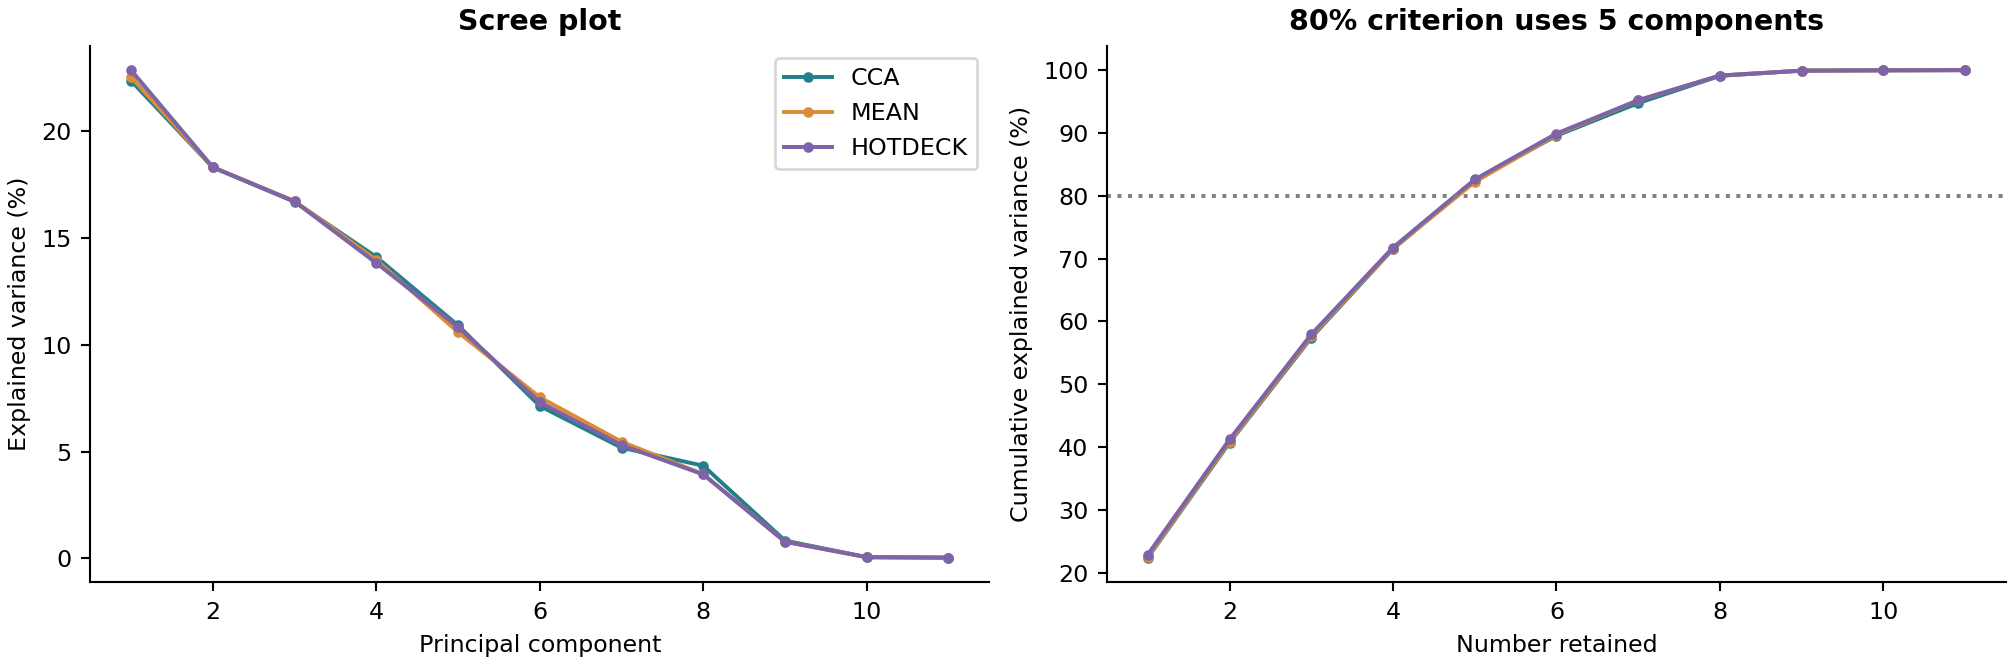

,strategy,pc1_cosine,pc2_cosine,pc1_score_r,pc2_score_r,top2_max_angle_deg,top3_max_angle_deg,top3_axis_matching
0,CCA,1.000000,1.000000,1.000000,1.000000,1.013607e-15,1.268651e-14,"1,2,3"
1,MEAN,0.992350,0.999152,0.995842,0.998486,6.961029e+00,1.422108e+01,"1,2,3"
2,HOTDECK,0.990833,0.999263,0.995611,0.998642,7.696421e+00,1.325024e+01,"1,2,3"


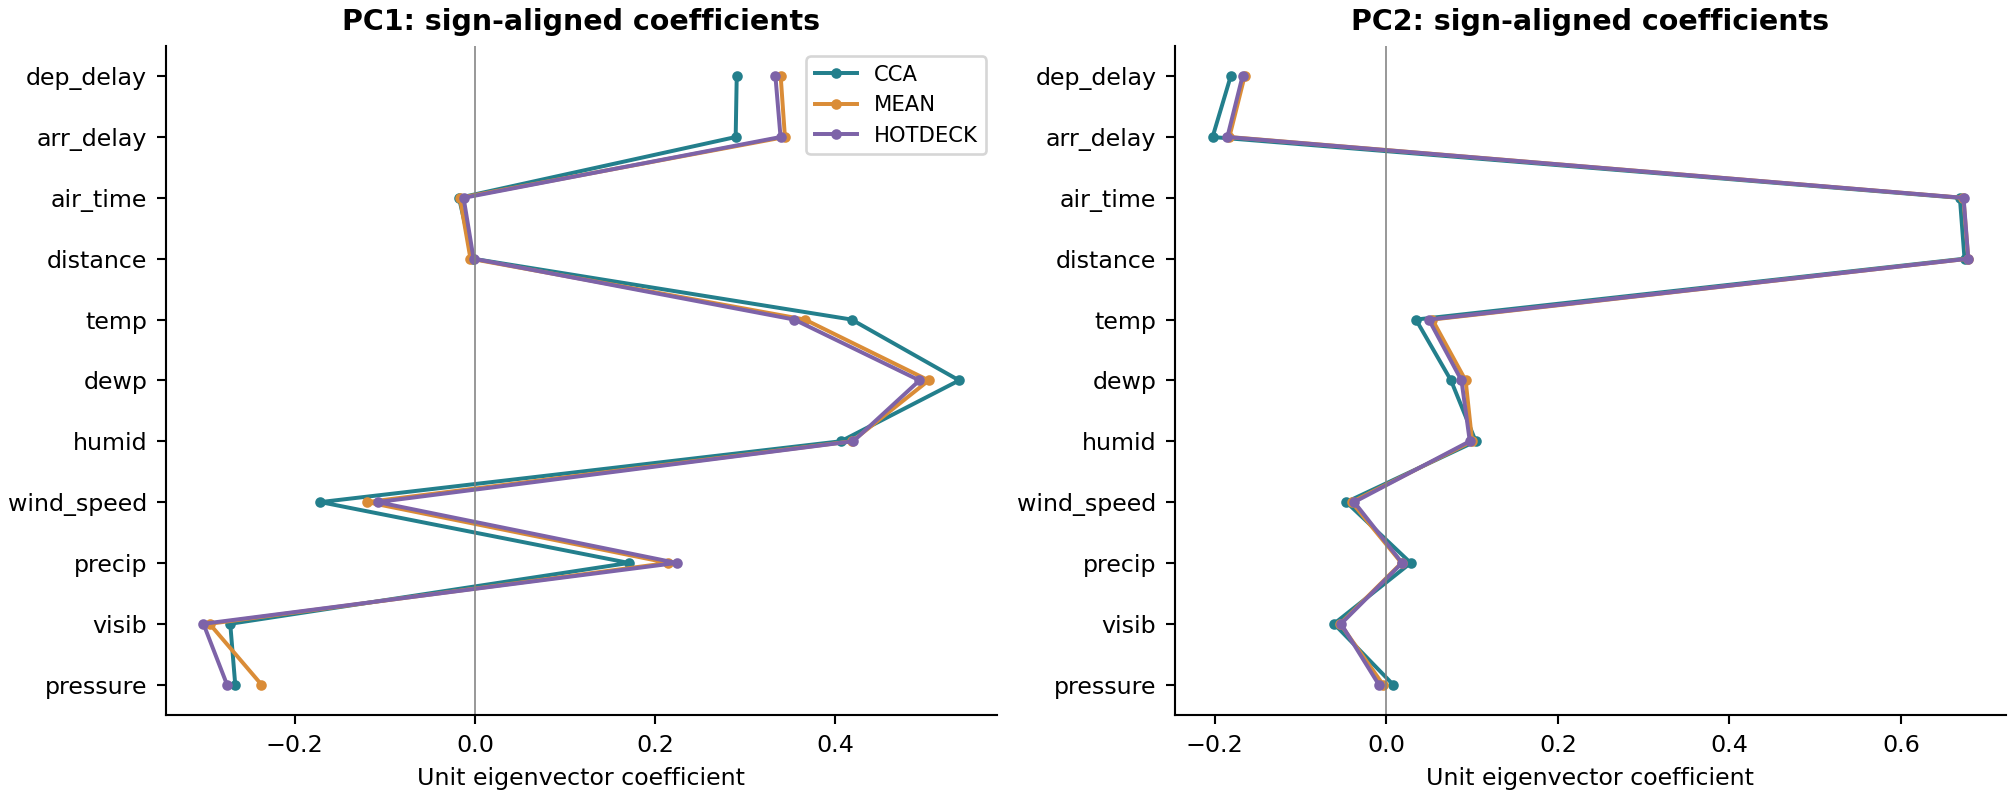

,check,strategy,n,pc1_cosine,pc2_cosine,pc1_score_r,pc2_score_r,top2_max_angle_deg,top3_max_angle_deg,top3_axis_matching
0,fixed_HOTDECK_scale,CCA,291140,1.000000,1.000000,1.000000,1.000000,2.172250e-14,3.915354e-14,"1,2,3"
1,fixed_HOTDECK_scale,MEAN,327346,0.919168,0.989836,0.957737,0.991837,2.341472e+01,2.226919e+01,"1,2,3"
2,fixed_HOTDECK_scale,HOTDECK,327346,0.916830,0.989547,0.957043,0.991696,2.374110e+01,2.214501e+01,"1,2,3"
3,exclude_unmatched_hours,HOTDECK,325819,0.999996,0.999995,0.999998,0.999997,2.226043e-01,2.241292e-01,"1,2,3"
4,retain_raw_wind,CCA,291140,1.000000,1.000000,1.000000,1.000000,1.159823e-10,9.360857e-11,"1,2,3"


In [7]:
# 第四部分：檢查保留成分數、PC1／PC2 方向與固定尺度後的敏感度。
display(Image(filename=str(ROOT/'output/figures/scree.png')))
display(pd.read_csv(ROOT/'output/tables/pca_stability.csv'))
display(Image(filename=str(ROOT/'output/figures/loading_comparison.png')))
display(pd.read_csv(ROOT/'output/tables/additional_sensitivity.csv'))

### 4.1 Live 互動工具
執行下一格後，可 hover 航班與負荷量、用下拉選單篩選、拖曳矩形框選，或勾選子群重新估計 PCA。繪圖最多 8,000 點，矩形幾何邊界會套用到全部篩選後航班計算摘要。若 widget 前端未安裝，直接以瀏覽器開啟 output/interactive/flight_explorer.html。

注意：重新擬合會換座標系；不要把換座標系後的點位移當成同一軸上的改變。

In [8]:
# 互動探索：可篩選、框選與重估子群 PCA；摘要仍由全資料計算。
from explorer import Explorer, make_snapshots
ex = Explorer()
panel = ex.widget()
display(panel)

,origin,n,arr_delay_mean
0,EWR,117127,9.107055
1,JFK,109079,5.551481
2,LGA,101140,5.783488


### 4.2 保留的六個操作與發現
下面各格真的重新執行篩選／幾何框選，並顯示該操作產生的圖。PNG 也獨立儲存在 output/screenshots。用互動介面重做時，可對照此處的條件、全資料 n 與平均值。

In [9]:
# 依相同參數重建六次操作，保存圖像與可核對的完整樣本數。
operations = make_snapshots()
print('已重建', len(operations), '個操作紀錄與圖像')

01_overview {'strategy': 'HOTDECK', 'origin': 'all', 'carrier': 'all', 'month': 'all', 'time_band': 'all', 'rain': 'all', 'pressure': 'all', 'brush': None, 'refit': False, 'refit_requested': False, 'refit_note': '', 'n': 327346, 'n_before_brush': 327346, 'arr_delay_mean': 6.89537675731489, 'distance_mean': 1048.3713135336923, 'air_time_mean': 150.68646019807787, 'original_pressure_missing_pct': 11.04091695026058, 'airport_counts': {'EWR': 117127, 'JFK': 109079, 'LGA': 101140}}
02_complete_cases {'strategy': 'CCA', 'origin': 'all', 'carrier': 'all', 'month': 'all', 'time_band': 'all', 'rain': 'all', 'pressure': 'all', 'brush': None, 'refit': False, 'refit_requested': False, 'refit_note': '', 'n': 291140, 'n_before_brush': 291140, 'arr_delay_mean': 4.759624235762863, 'distance_mean': 1045.7483513086488, 'air_time_mean': 150.16748986741774, 'original_pressure_missing_pct': 0.0, 'airport_counts': {'EWR': 103461, 'JFK': 97731, 'LGA': 89948}}
03_rain_missing {'strategy': 'HOTDECK', 'origin':

#### 操作 1：Mechanism-aware analysis: all eligible flights

**這個操作讓我發現了什麼：** 全適用母體共有 327,346 班，平均抵達延誤 6.90 分鐘。先確認參考群體與模型，再解讀分群。

strategy                                                               HOTDECK
origin                                                                     all
carrier                                                                    all
month                                                                      all
time_band                                                                  all
rain                                                                       all
pressure                                                                   all
brush                                                                     None
refit                                                                    False
refit_requested                                                          False
refit_note                                                                    
n                                                                       327346
n_before_brush                                      

,origin,n,arr_delay_mean
0,EWR,117127,9.107055
1,JFK,109079,5.551481
2,LGA,101140,5.783488


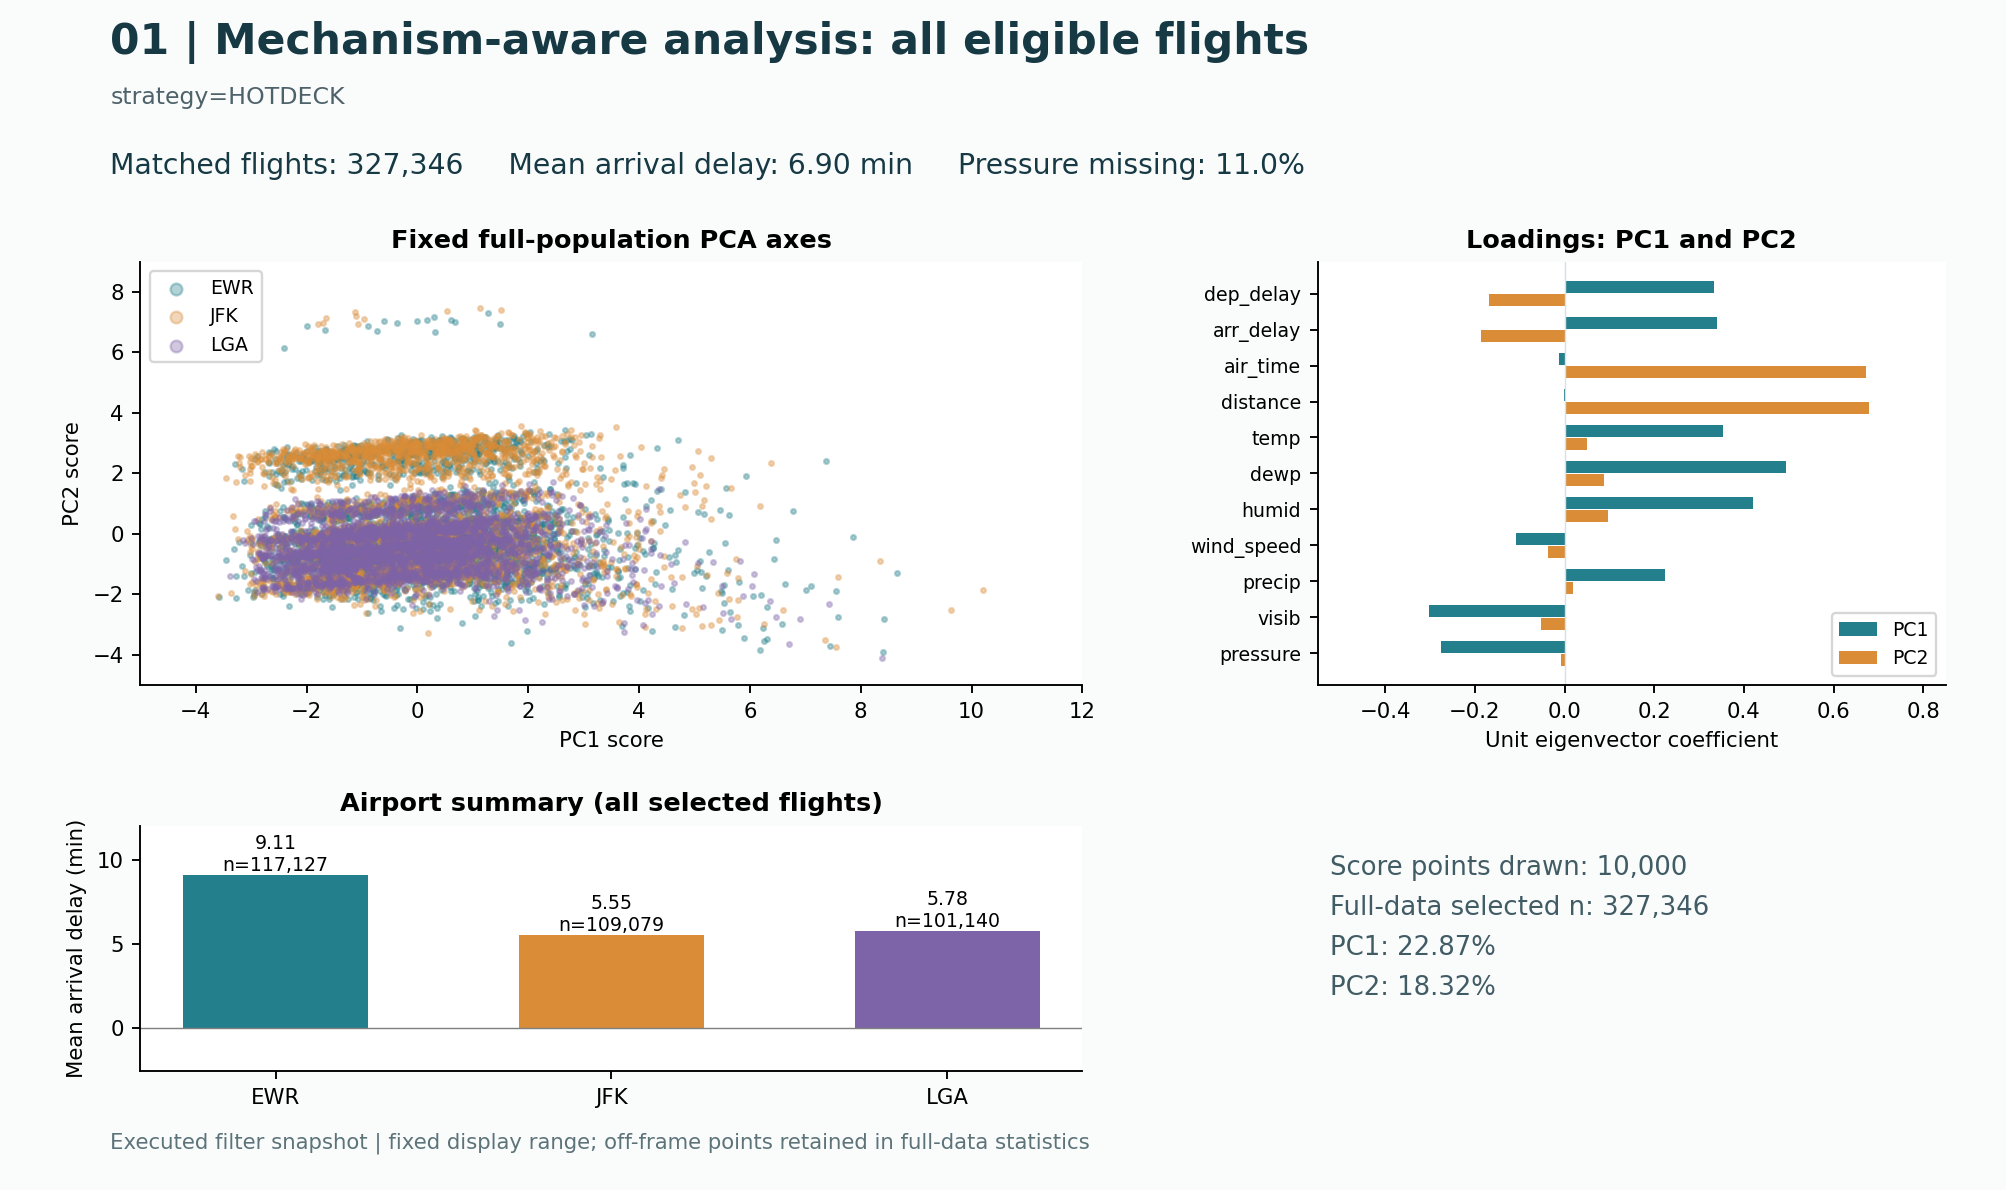

In [10]:
# 操作 1：依下列篩選條件重算摘要，並展示相應的分析圖。
result = ex.select(strategy='HOTDECK')
display(pd.Series(result['summary'], name='完整資料操作結果'))
display(result['airports'])
display(Image(filename=str(ROOT/'output/screenshots/01_overview.png')))

#### 操作 2：Switch to complete-case analysis

**這個操作讓我發現了什麼：** 只換成 CCA，少了 36,206 班、平均延誤降至 4.76 分鐘；散布圖相似並不表示樣本選擇無影響。

strategy                                                                 CCA
origin                                                                   all
carrier                                                                  all
month                                                                    all
time_band                                                                all
rain                                                                     all
pressure                                                                 all
brush                                                                   None
refit                                                                  False
refit_requested                                                        False
refit_note                                                                  
n                                                                     291140
n_before_brush                                                        291140

,origin,n,arr_delay_mean
0,EWR,103461,7.032466
1,JFK,97731,3.288312
2,LGA,89948,3.743952


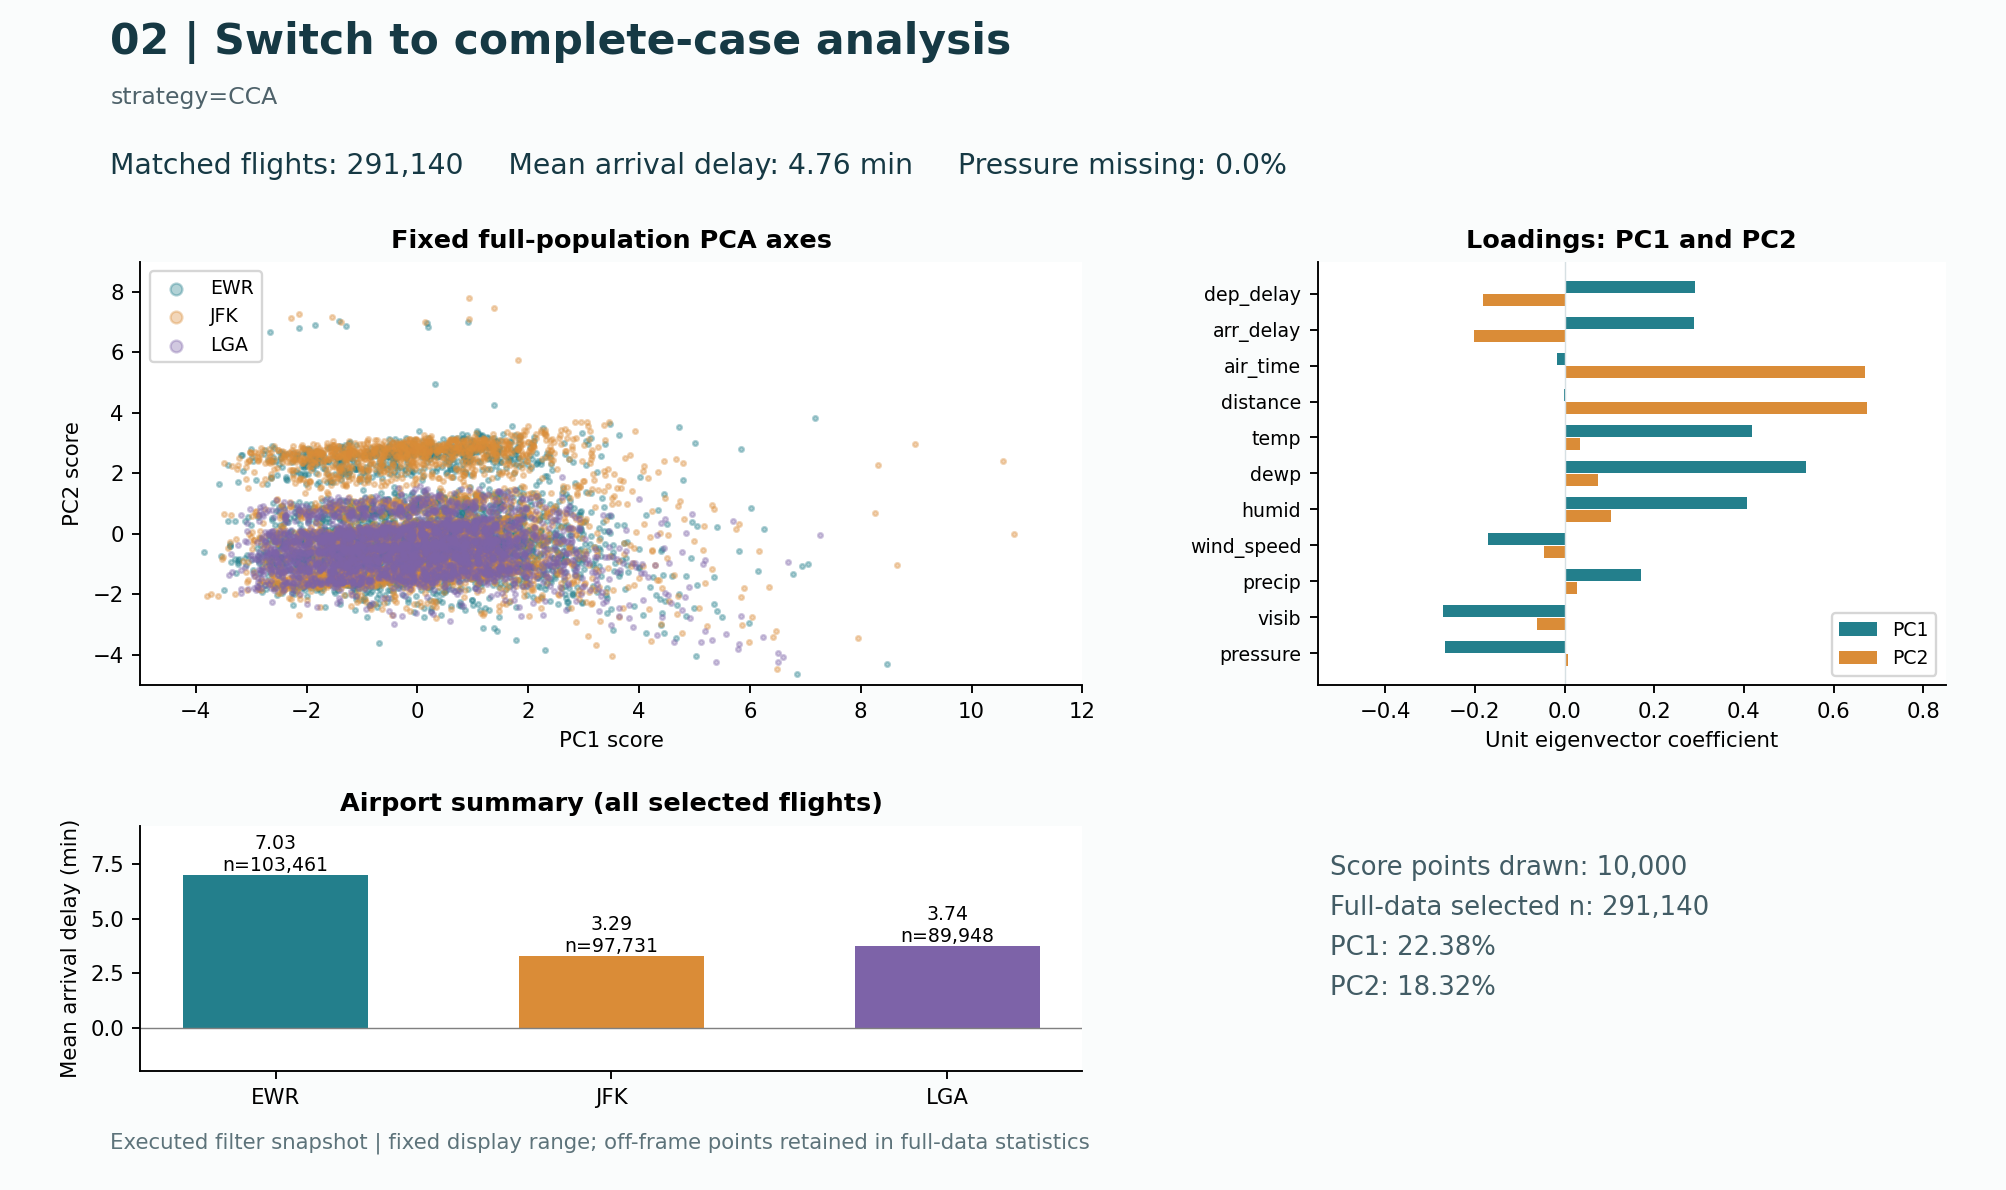

In [11]:
# 操作 2：依下列篩選條件重算摘要，並展示相應的分析圖。
result = ex.select(strategy='CCA')
display(pd.Series(result['summary'], name='完整資料操作結果'))
display(result['airports'])
display(Image(filename=str(ROOT/'output/screenshots/02_complete_cases.png')))

#### 操作 3：Rainy flights with missing pressure

**這個操作讓我發現了什麼：** 11,915 班有雨且氣壓缺失，平均延誤 39.18 分鐘；整群會被 CCA 排除，這是從交叉篩選定位的關鍵群體。

strategy                                                         HOTDECK
origin                                                               all
carrier                                                              all
month                                                                all
time_band                                                            all
rain                                                                rain
pressure                                                         missing
brush                                                               None
refit                                                              False
refit_requested                                                    False
refit_note                                                              
n                                                                  11915
n_before_brush                                                     11915
arr_delay_mean                                     

,origin,n,arr_delay_mean
0,EWR,4617,39.870695
1,JFK,3512,42.113895
2,LGA,3786,35.615425


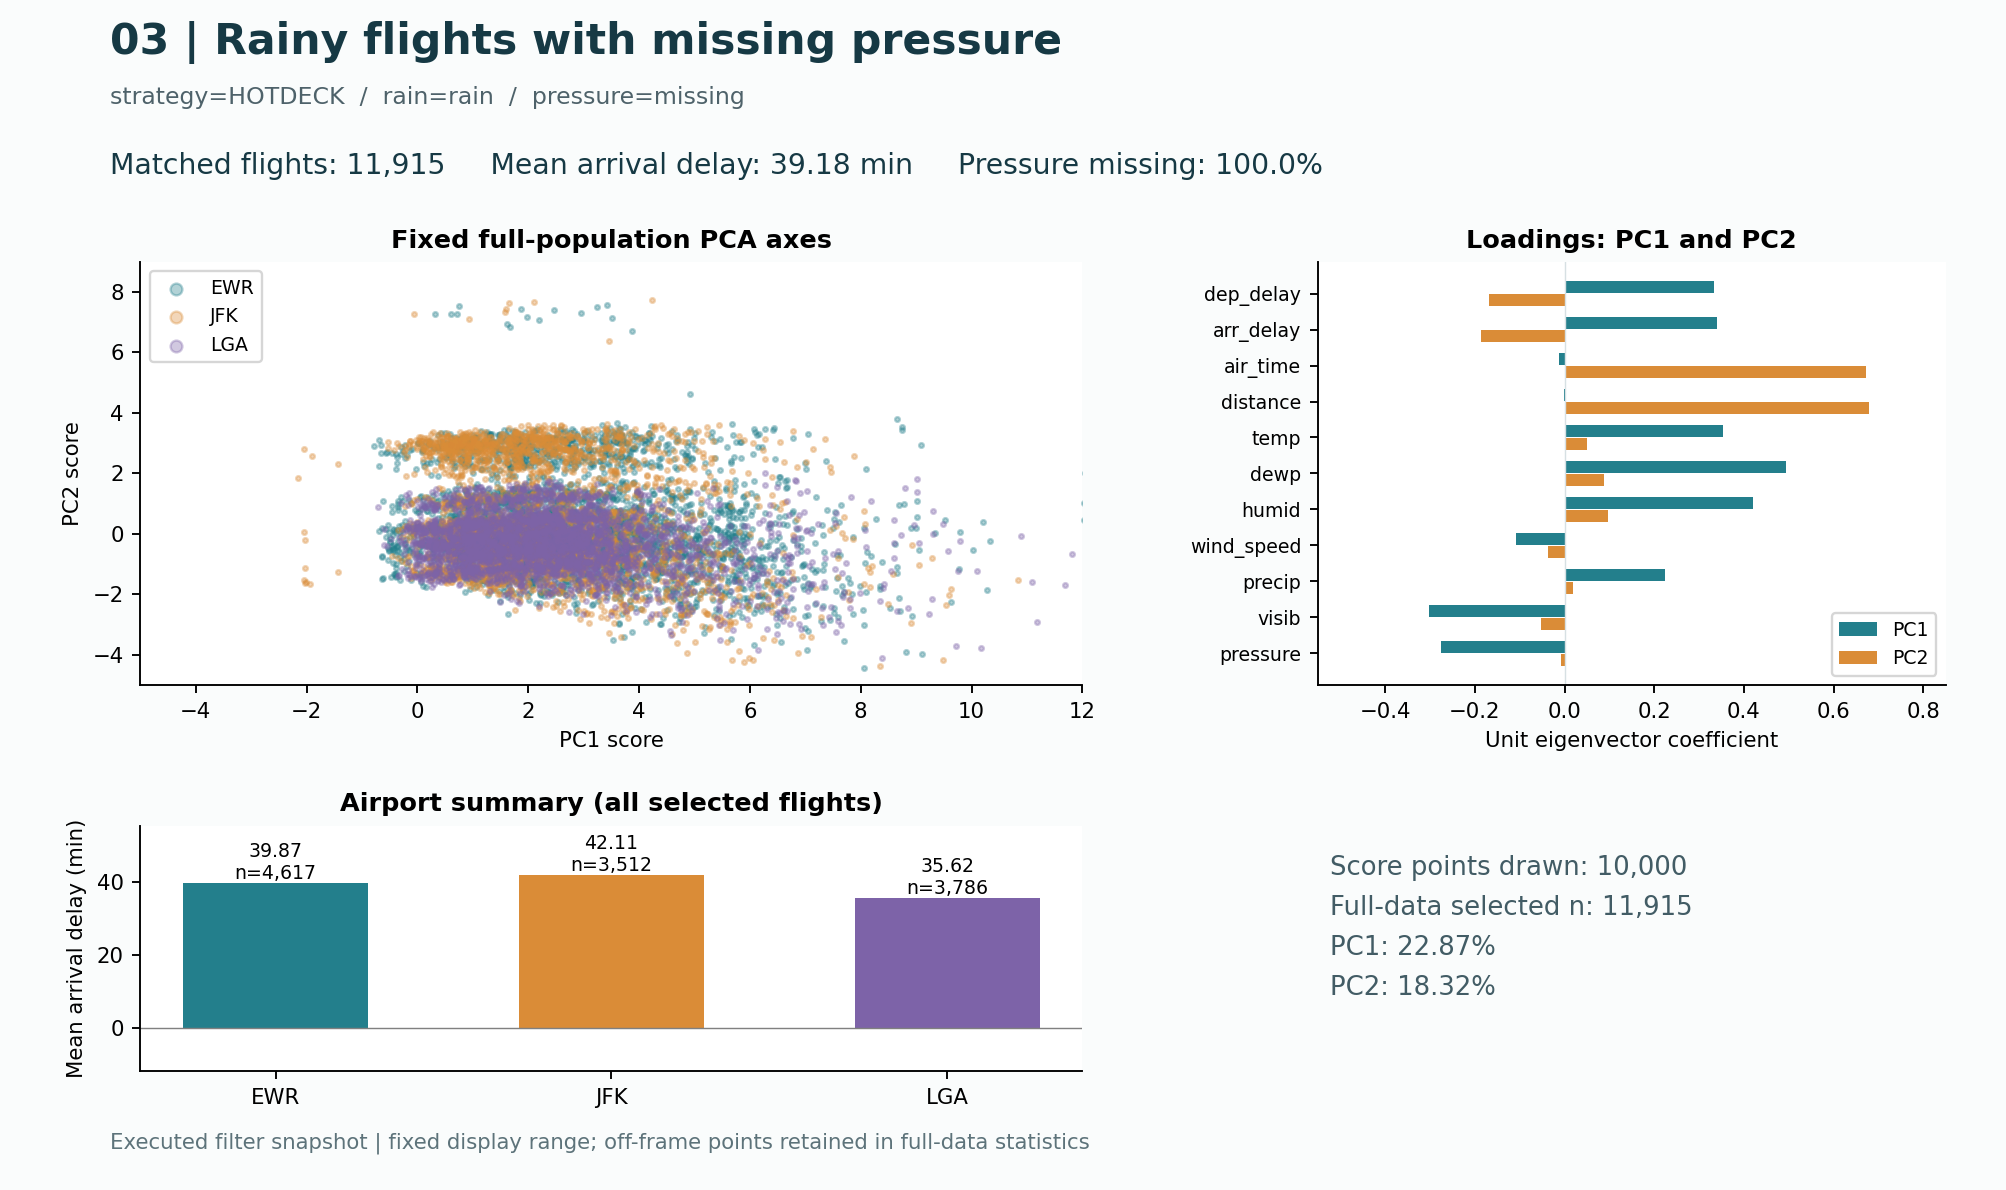

In [12]:
# 操作 3：依下列篩選條件重算摘要，並展示相應的分析圖。
result = ex.select(strategy='HOTDECK', rain='rain', pressure='missing')
display(pd.Series(result['summary'], name='完整資料操作結果'))
display(result['airports'])
display(Image(filename=str(ROOT/'output/screenshots/03_rain_missing.png')))

#### 操作 4：Hold carrier fixed: United Airlines

**這個操作讓我發現了什麼：** UA 的 57,782 班在機場分布不均：EWR 45,501、JFK 4,478、LGA 7,803；機場均值比較受航空公司與航程組成影響。

strategy                                                          HOTDECK
origin                                                                all
carrier                                                                UA
month                                                                 all
time_band                                                             all
rain                                                                  all
pressure                                                              all
brush                                                                None
refit                                                               False
refit_requested                                                     False
refit_note                                                               
n                                                                   57782
n_before_brush                                                      57782
arr_delay_mean                        

,origin,n,arr_delay_mean
0,EWR,45501,3.475176
1,JFK,4478,2.510496
2,LGA,7803,4.642189


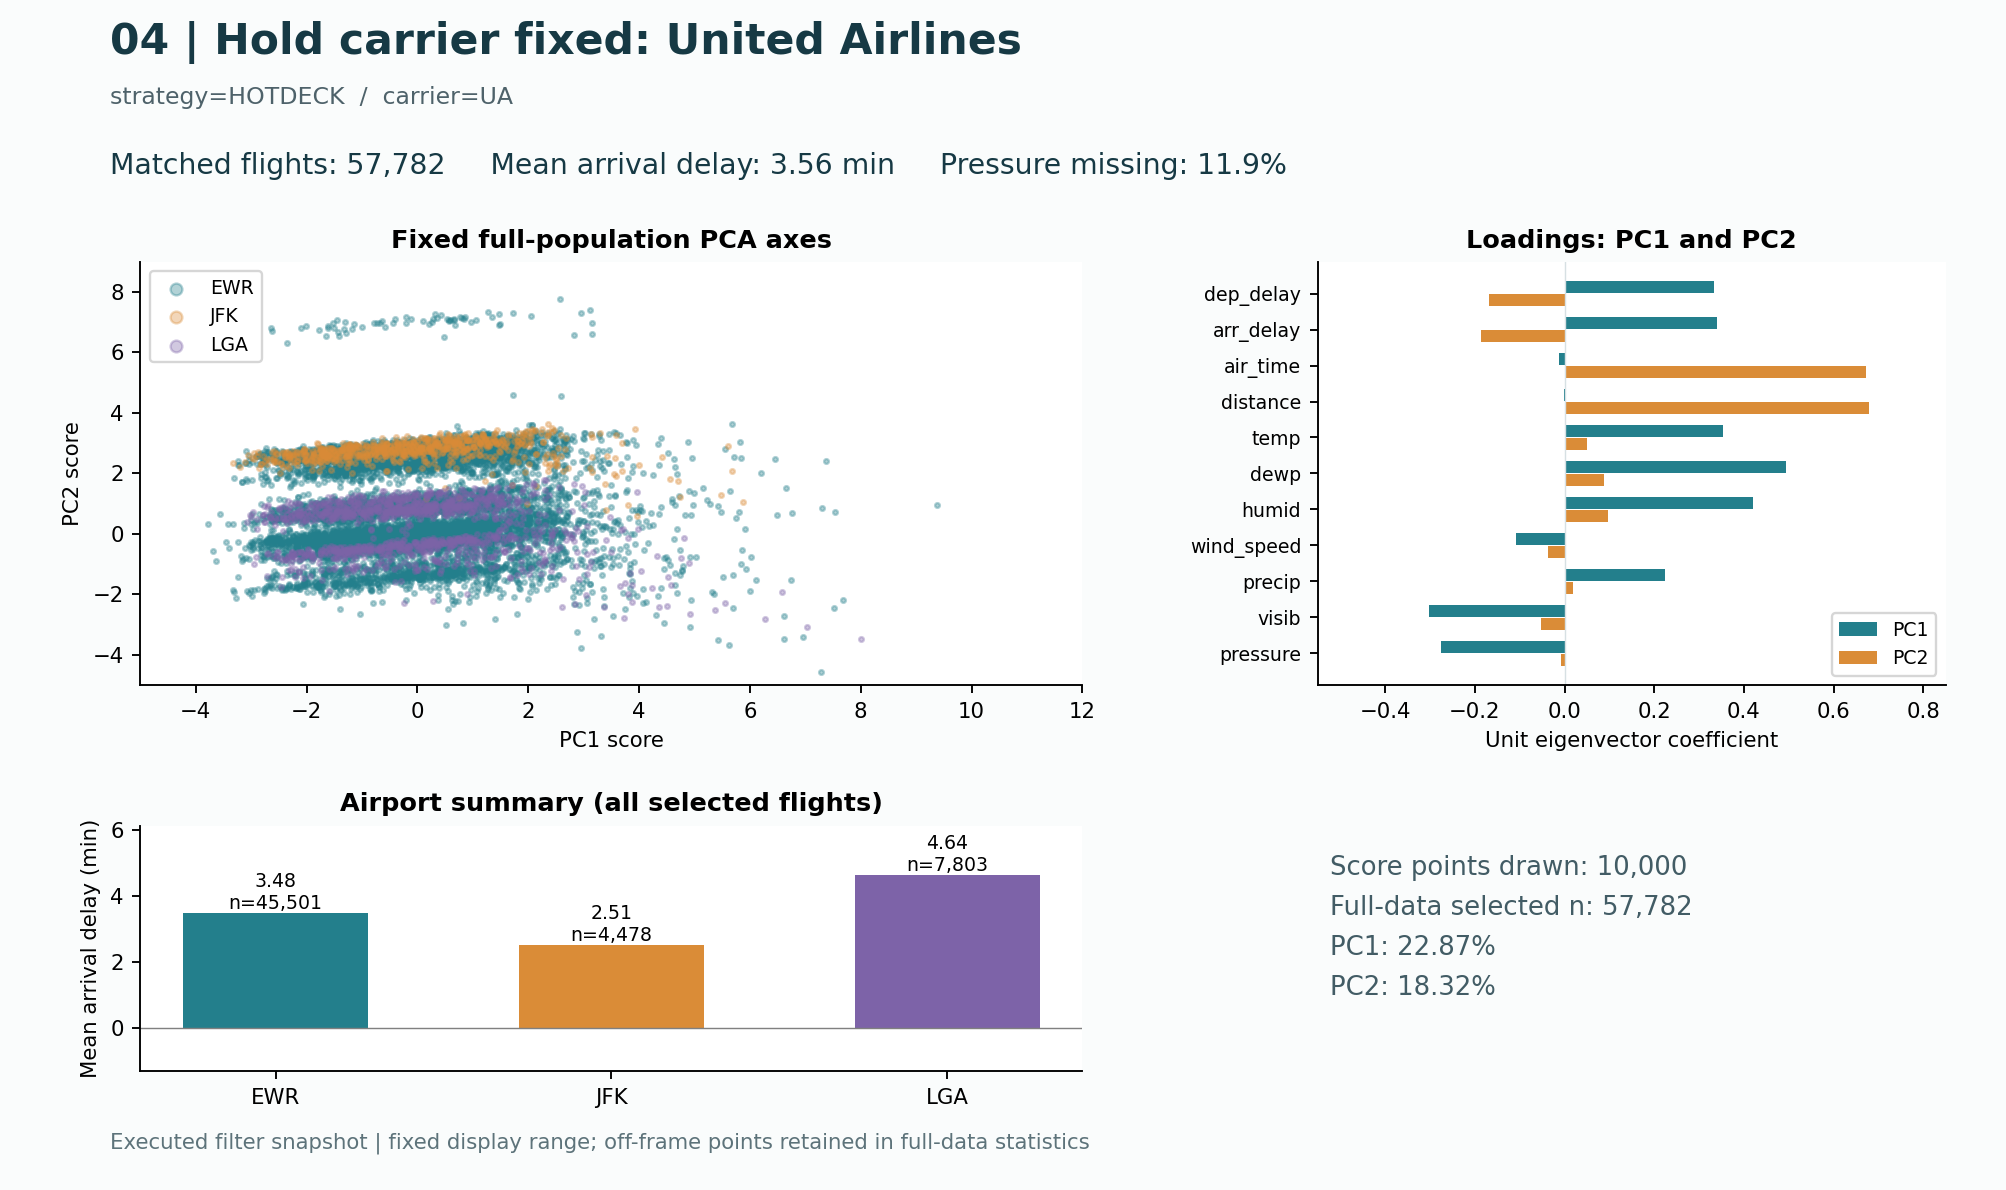

In [13]:
# 操作 4：依下列篩選條件重算摘要，並展示相應的分析圖。
result = ex.select(strategy='HOTDECK', carrier='UA')
display(pd.Series(result['summary'], name='完整資料操作結果'))
display(result['airports'])
display(Image(filename=str(ROOT/'output/screenshots/04_carrier_ua.png')))

#### 操作 5：Brush the high-PC2 region

**這個操作讓我發現了什麼：** 本機參考結果為矩形內約 4.7 萬班、平均距離約 2,480 英里、平均延誤約 -5 分鐘，沒有 LGA。重跑時請以本格實際輸出為準；高 PC2 主要是航程，而不是延誤程度。

strategy                                              HOTDECK
origin                                                    all
carrier                                                   all
month                                                     all
time_band                                                 all
rain                                                      all
pressure                                                  all
brush                                           [-4, 4, 2, 8]
refit                                                   False
refit_requested                                         False
refit_note                                                   
n                                                       47477
n_before_brush                                         327346
arr_delay_mean                                      -5.040019
distance_mean                                     2479.069402
air_time_mean                                      331.711882
original

,origin,n,arr_delay_mean
0,EWR,17215,-4.831194
1,JFK,30262,-5.158813
2,LGA,0,NaN


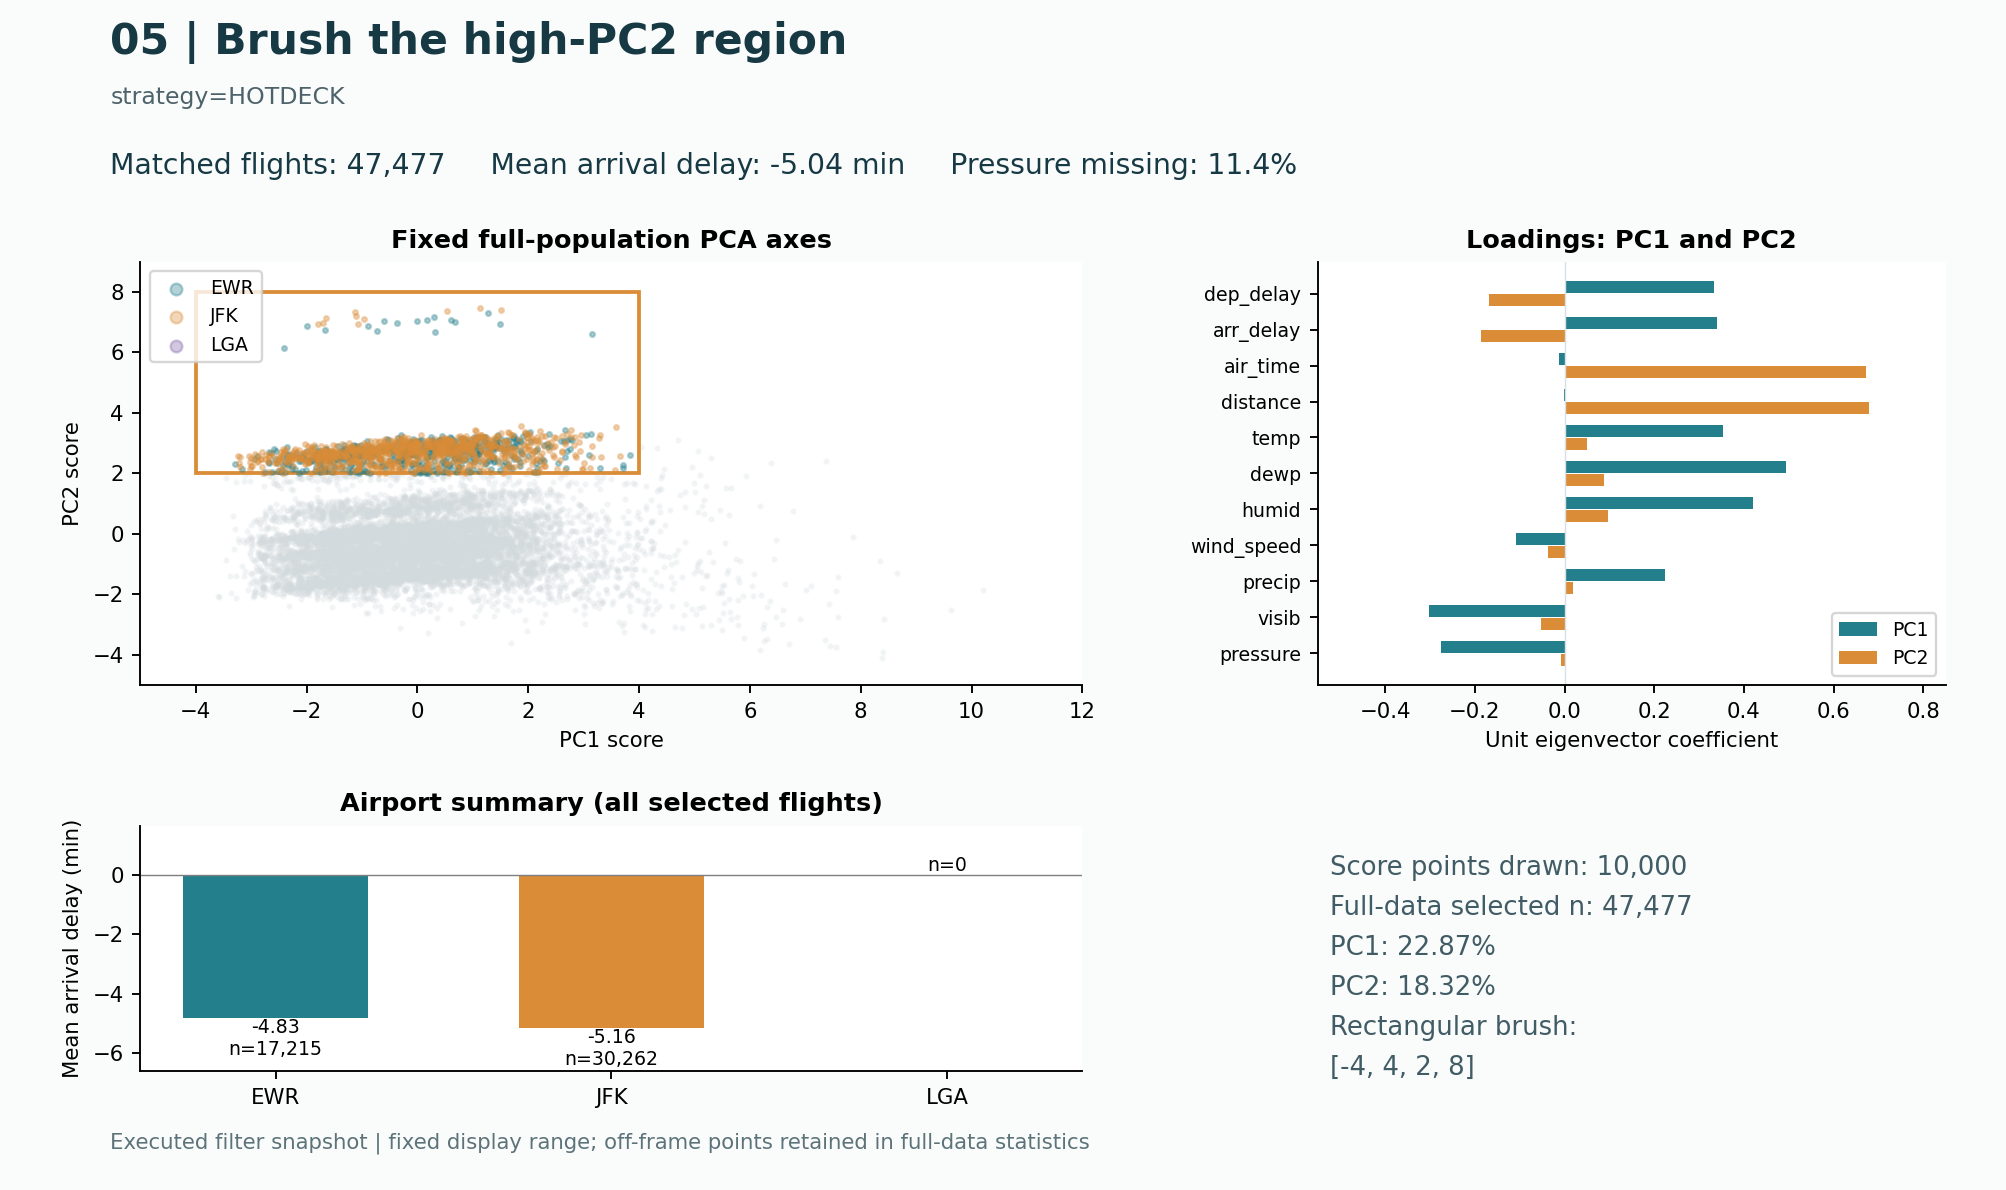

In [14]:
# 操作 5：依下列篩選條件重算摘要，並展示相應的分析圖。
result = ex.select(strategy='HOTDECK', brush=[-4, 4, 2, 8])
display(pd.Series(result['summary'], name='完整資料操作結果'))
display(result['airports'])
display(Image(filename=str(ROOT/'output/screenshots/05_brush_longhaul.png')))

#### 操作 6：Refit PCA within LGA

**這個操作讓我發現了什麼：** LGA 子群 101,140 班平均航程 785 英里。重估後 PC2 的抵達延誤係數由 -0.185 變成 +0.176，溫度由 +0.050 變成 -0.274，而距離仍為正向。這不是單純整軸正負號翻轉，子群中的混合意義確實不同；不能與原固定座標直接比較。

strategy                                 HOTDECK
origin                                       LGA
carrier                                      all
month                                        all
time_band                                    all
rain                                         all
pressure                                     all
brush                                       None
refit                                       True
refit_requested                             True
refit_note                                      
n                                         101140
n_before_brush                            101140
arr_delay_mean                          5.783488
distance_mean                          784.75611
air_time_mean                         117.825806
original_pressure_missing_pct          11.065849
airport_counts                   {'LGA': 101140}
Name: 完整資料操作結果, dtype: object

,origin,n,arr_delay_mean
0,EWR,0,NaN
1,JFK,0,NaN
2,LGA,101140,5.783488


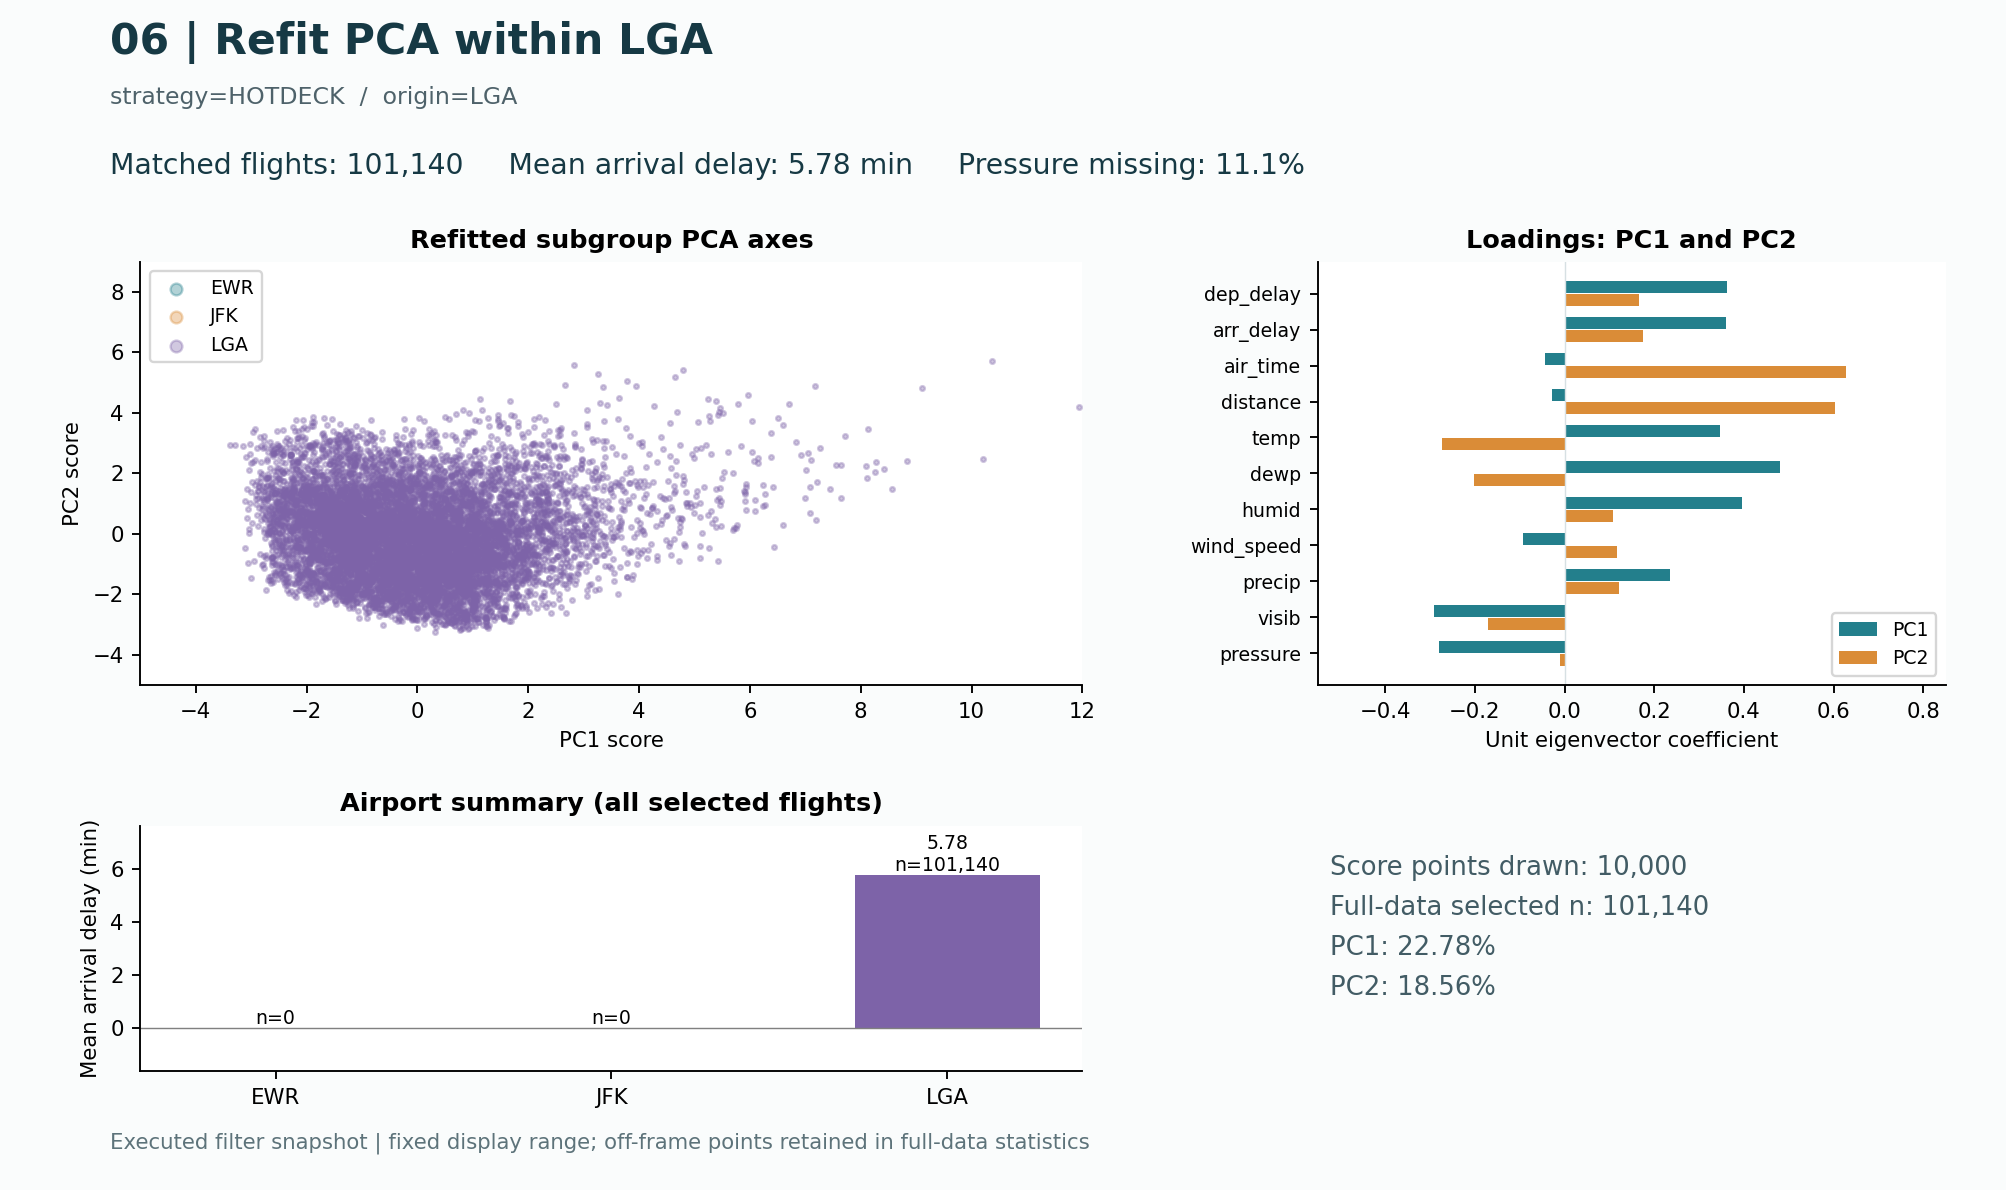

In [15]:
# 操作 6：依下列篩選條件重算摘要，並展示相應的分析圖。
result = ex.select(strategy='HOTDECK', origin='LGA', refit=True)
display(pd.Series(result['summary'], name='完整資料操作結果'))
display(result['airports'])
display(Image(filename=str(ROOT/'output/screenshots/06_subgroup_pca.png')))

### 機場分層延伸
先限定三機場皆有足夠樣本的共同航空公司×月份×時段格子，再比較共同組成加權的機場均值。此處仍沒有調整航線及所有天氣，不能視為因果效果。

In [16]:
# 額外按航空公司、月份與時段限制共同組成，檢查機場均值差異。
display(pd.read_csv(ROOT/'output/tables/airport_delay.csv'))
display(pd.read_csv(ROOT/'output/tables/airport_standardized.csv'))

,origin,size,mean,median,std,strategy
0,EWR,117127,9.107055,-4.0,45.529183,available_arr_delay
1,JFK,109079,5.551481,-6.0,44.277448,available_arr_delay
2,LGA,101140,5.783488,-5.0,43.862273,available_arr_delay
3,EWR,117127,9.107055,-4.0,45.529183,eligible
4,JFK,109079,5.551481,-6.0,44.277448,eligible
5,LGA,101140,5.783488,-5.0,43.862273,eligible
6,EWR,103461,7.032466,-4.0,42.892662,CCA
7,JFK,97731,3.288312,-7.0,41.501004,CCA
8,LGA,89948,3.743952,-6.0,41.231589,CCA


,origin,size,common_unadjusted,standardized_mean,common_cells,eligible_coverage_pct
0,EWR,107505,9.386159,9.235694,266,91.784986
1,JFK,95611,5.116273,6.892638,266,87.652985
2,LGA,88301,4.958121,7.612492,266,87.305715


## 5. 反思（AI 協助草稿，請依本人理解審閱）

這次分析讓我重新理解「資料清乾淨」的意思。AI 初版正確指出延誤呈右偏分布、距離與空中時間高度相關，也有標準化不同單位，並提醒機場平均不能直接解讀成機場效率。它沒有把所有類別代碼丟進 PCA，也沒有把取消航班補成零。因此，對照的重點不是刻意找 AI 的錯，而是追問它尚未完成哪些檢驗。

初版最重要的未檢驗預設，是先用完整個案描繪資料結構。這個做法保留了很多航班，看似足夠，卻沒有回答被排除的是誰。正式診斷發現，氣壓缺失時段的濕度較高、能見度較低，降雨比例也遠高於完整時段。缺失可以被其他觀測變數預測，單純以隨機遺漏理解並不合理。不過，這些關聯只能支持一個有條件的插補假設，不能證明 MAR，更不能排除未觀測天氣或量測流程造成的 MNAR。

最有幫助的操作，是在保存的探索紀錄中，同時篩選「有降雨」及「氣壓缺失」。這群航班的平均抵達延誤約三十九分鐘，卻會被完整列刪除整批排除。只看全部資料的缺失比例，很難感受到這個差異。另一個框選操作則顯示，高 PC2 區域主要是長程航班，平均反而提早抵達，而且沒有 LGA 航班。這提醒我，圖上分群必須回到原始變數核對，不能看到遠離中心的點就把它命名為延誤異常。

敏感度分析也修正了我的期待。三種策略的前兩軸沒有劇烈翻轉，完整列刪除卻把平均抵達延誤從六點九分鐘降到四點八分鐘。結構穩定與描述統計偏移可以同時存在。進一步固定標準化尺度後，方向差異又變大，所以「PCA 穩定」必須連同尺度選擇一起說明，不能只展示外觀相近的散布圖。

條件式熱卡插補仍有侷限。它假設同機場、同月份、觀測條件相近的時段可以提供合理供體，無法還原完全未觀測時段的真實天氣。二十次抽取的變動範圍也不是信賴區間。這份作業最重要的收穫，是把分析母體、缺失來源及方法假設寫成可以檢查的決策；AI 可以協助計算與整理，但結論的適用範圍仍需要研究者負責說清楚。


## 可重現性與限制
- 原始 CSV、固定 Git blob 與 SHA-256：data/raw 與 src/download_data.py。
- AI 基準全文及其封存清單：baseline/。
- 所有表格：output/tables；20 次抽取的差異是演算法敏感度，不是信賴區間。
- output/screenshots/operation_log.json 保留全部篩選、框選界線與結果。
- 資料來源與課堂參考見 README 與 PDF。
- 這份 notebook 的預存輸出以 IPython 同一行程實際執行產生；live widget 前端視覺 QA 因環境限制未完成。

In [17]:
# 最後核對本次新算的核心結果、六個互動操作與原始檔雜湊。
from math import isclose
summary = pd.read_csv(ROOT/'output/tables/strategy_summary.csv').set_index('strategy')
results = json.loads((ROOT/'output/results.json').read_text())
records = json.loads((ROOT/'output/screenshots/operations.json').read_text())
assert results['draws'] == 20 and results['n_total'] == 336776 and results['n_eligible'] == 327346
assert int(summary.loc['CCA','n']) == 291140
assert int(summary.loc['HOTDECK','n']) == 327346
assert isclose(summary.loc['HOTDECK','arr_delay_mean'], 6.89537675731489, abs_tol=1e-8)
assert len(records) == 6 and all((ROOT / row['image']).is_file() for row in records)
counts = [row['n'] for row in records]
print('六個操作的本次樣本數：', counts)
# 非框選操作是資料篩選，樣本數必須一致；矩形邊界上的 PCA 分數會受數值套件版本影響。
assert [counts[i] for i in (0,1,2,3,5)] == [327346, 291140, 11915, 57782, 101140]
brush = records[4]
assert 45000 <= brush['n'] <= 50000, f'框選樣本數異常：{brush["n"]}'
assert 2300 <= brush['distance_mean'] <= 2600, '框選平均航程與長程群的發現不符'
assert -8 <= brush['arr_delay_mean'] <= -2, '框選平均延誤與原發現不符'
assert brush['airport_counts'].get('LGA', 0) == 0, '框選出現 LGA；請檢查 PCA 座標方向'
print('原始檔案核對：')
verify_or_download()
display(json.loads((ROOT/'output/environment.json').read_text()))
print('重現成功：原始資料、三種策略、20 次熱卡、PCA 與六個互動操作均已重新產生並通過核對。')

六個操作的本次樣本數： [327346, 291140, 11915, 57782, 47477, 101140]
原始檔案核對：
flights 33206996 bytes: SHA-256 and Git blob verified
weather 2391865 bytes: SHA-256 and Git blob verified
重現成功：原始資料、三種策略、20 次熱卡、PCA 與六個互動操作均已重新產生並通過核對。


{'python': '3.11.7 (main, Dec 15 2023, 12:09:04) [Clang 14.0.6 ]',
 'platform': 'macOS-10.16-x86_64-i386-64bit',
 'numpy': '1.26.4',
 'pandas': '2.1.4',
 'matplotlib': '3.8.0',
 'seed': 20261026,
 'draws': 20}

## 互動成果的繳交方式

已發布的 dashboard：<https://snazzy-beijinho-a8153e.netlify.app/>。老師公告接受「已發布的 dashboard 連結」**或**「至少五張操作截圖並逐張說明」。可在繳交欄貼上這個連結。

上方六個操作圖是此 notebook 實際執行篩選與矩形框選後產生的分析圖，逐張附有條件和發現；它們不是瀏覽器操作截圖。若老師另外指定必須交真實瀏覽器截圖，再從 dashboard 親自操作與擷取。